<style>
.jp-CodeCell .jp-InputArea, div.input_area {background:#eef8ee !important; border-left:5px solid #2e7d32 !important;}
.jp-CodeCell pre, div.input_area pre {color:#145a20 !important;}
.note-box {background:#eef5ff; border-left:5px solid #2f5597; padding:12px; margin:10px 0;}
.warning-box {background:#fff4e5; border-left:5px solid #d97706; padding:12px; margin:10px 0;}
.success-box {background:#edf7ed; border-left:5px solid #2e7d32; padding:12px; margin:10px 0;}
.decision-box {background:#f7f4ff; border-left:5px solid #6b46c1; padding:12px; margin:10px 0;}
</style>

        # SBI 812: Machine Learning in Bioinformatics
        ## Lecture 4 — Decision Trees, Random Forests and K-Nearest Neighbours

        **Duration:** 3 hours  
        **Level:** Introductory  
        **Prerequisite:** Lecture 3 — preparing data and fitting a first classifier  
        **Practical outcome:** Understand three classification algorithms visually and implement them directly with scikit-learn

        This lecture continues with:

        ```text
        lecture03_bacterial_response.csv
        ```

        Place the CSV file in the same directory as this notebook.


## 1. What is new in this lecture?

Lecture 3 established the general machine-learning workflow: select appropriate features, separate training and test data, preprocess the features, fit a classifier and evaluate its predictions.

This lecture does not rebuild that theory. It asks a new question:

> **How do different classification algorithms decide which class a sample belongs to?**

Three algorithms will be studied:

1. **Decision tree** — follows a sequence of feature-based questions.
2. **Random forest** — combines votes from many decision trees.
3. **K-nearest neighbours** — uses the classes of nearby training samples.

Each algorithm is first understood with a diagram and then implemented directly using scikit-learn. We will not write these algorithms from scratch.


## Learning outcomes

By the end of the lecture, you should be able to:

1. identify the root, internal nodes, branches and leaves of a decision tree;
2. follow a sample through a decision-tree diagram;
3. explain how a tree converts feature values into a class prediction;
4. fit and visualize `DecisionTreeClassifier`;
5. explain why an unrestricted tree can overfit;
6. connect a decision tree to a random forest;
7. fit `RandomForestClassifier` and inspect feature importance cautiously;
8. explain the neighbour and distance ideas behind KNN;
9. explain why scaling matters for KNN;
10. fit `KNeighborsClassifier`; and
11. compare the predictions and limitations of the three algorithms.


# Part 1 — A short preparation step

The next cells load the same data and reproduce the preparation decisions already established in Lecture 3. The explanations are intentionally brief so that the lecture can concentrate on algorithms.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)


The three principal classifier classes are:

```python
DecisionTreeClassifier
RandomForestClassifier
KNeighborsClassifier
```

A class is a blueprint supplied by scikit-learn. Adding parentheses creates a configured estimator object. The object becomes a fitted model only after `.fit(...)` learns from data.


In [ ]:
data = pd.read_csv("lecture03_bacterial_response.csv")

print("Shape:", data.shape)
data.head()


Each row represents one bacterial sample. The target column is `response`, containing `sensitive` or `resistant`.


In [ ]:
feature_columns = [
    "species", "treatment", "batch", "time_h",
    "gene_a", "gene_b", "gene_c", "growth_rate"
]

X = data[feature_columns].copy()
y = data["response"].copy()
sample_ids = data["sample_id"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))


`sample_id` remains outside `X` because it is an identifier. `response_code` remains outside `X` because it encodes the answer. The same training and test rows will be used for all three classroom implementations.


In [ ]:
numeric_features = [
    "time_h", "gene_a", "gene_b", "gene_c", "growth_rate"
]

categorical_features = ["species", "treatment", "batch"]

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ]
)


This preprocessor fills missing values, scales numerical features and one-hot encodes categories. Keeping it inside each pipeline ensures that the classifier receives a numerical feature matrix.


# Part 2 — Decision trees: the full idea

A decision tree is a supervised learning algorithm that classifies a sample by asking a sequence of questions about its feature values.

The questions are not written manually by the researcher. During training, the algorithm examines possible features and thresholds and selects questions that separate the known classes as effectively as possible.

Before using scikit-learn, we will study one complete small example. The example shows:

1. the parts of a tree;
2. how a sample moves through the tree;
3. how Gini impurity measures class mixing;
4. how candidate splits are compared; and
5. how the best question becomes a node.


## 2.1 The complete tree and its labels

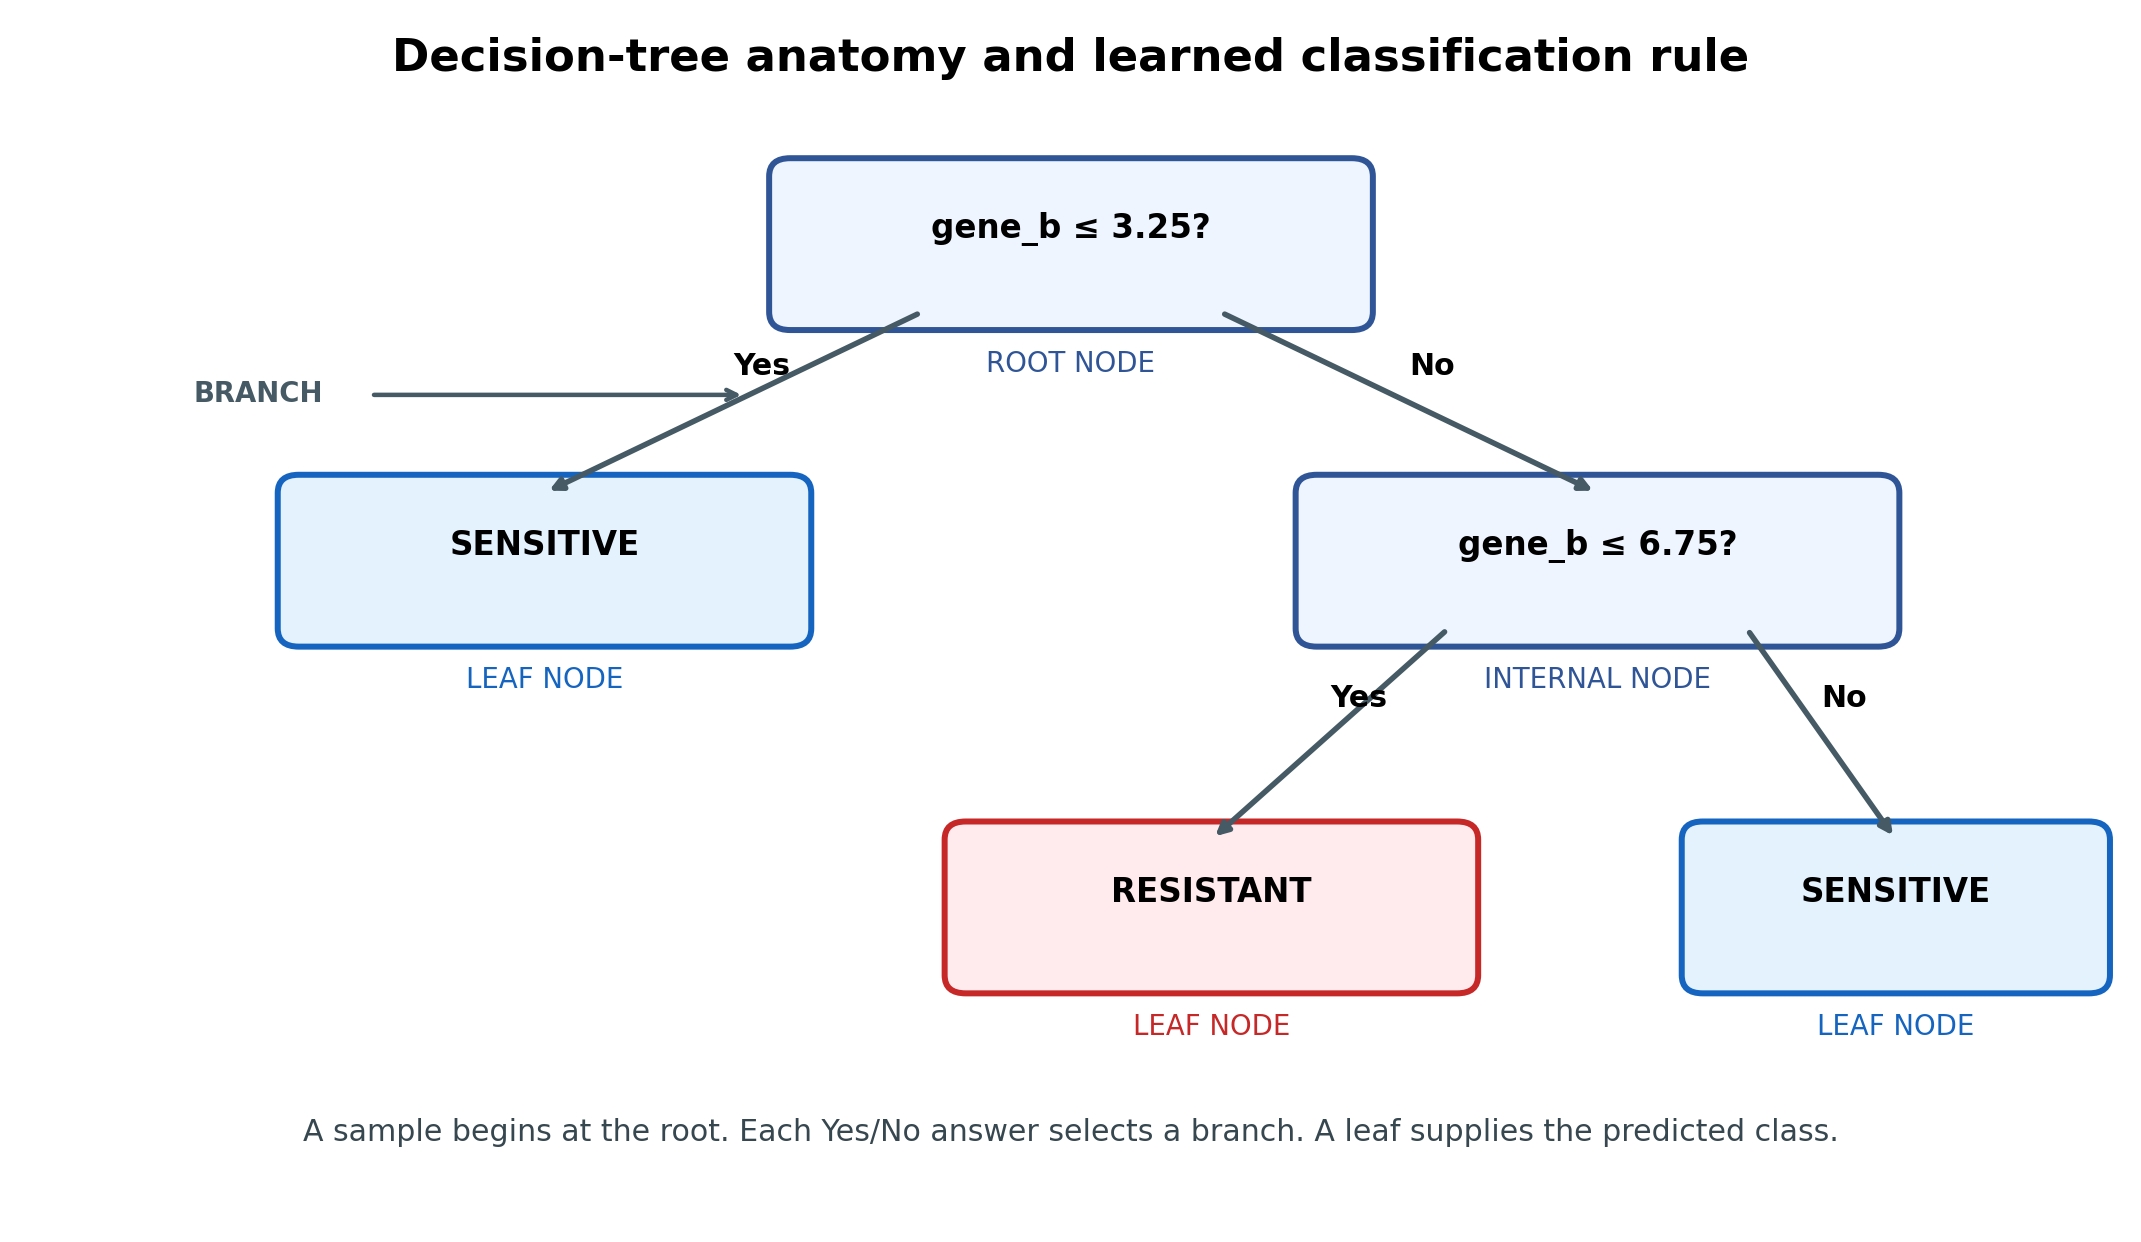

The image is embedded directly in the notebook as a PNG. It should therefore remain visible without running a code cell or opening another file.


## 2.2 Vocabulary used in a decision tree

**Root node**  
The first question in the tree. Every sample begins here. In the diagram, the root asks whether `gene_b ≤ 3.25`.

**Internal node**  
A later question reached after following a branch. The internal node asks whether `gene_b ≤ 6.75`.

**Branch**  
A path corresponding to an answer. For a numerical question, the answer is commonly `Yes` or `No`.

**Leaf node**  
The end of a path. A leaf does not ask another question; it returns the predicted class.

**Threshold**  
The value used in a question. In `gene_b ≤ 3.25`, the threshold is `3.25`.

**Depth**  
The number of decision levels along a path. A deeper tree can express more complicated rules, but it can also overfit.


## 2.3 The small training dataset used to build the tree

The following eight samples have one feature, `gene_b`, and a known response. The known responses are required because a decision tree is a supervised learning algorithm.

| Sample | `gene_b` | Known response |
|---|---:|---|
| S1 | 2.0 | sensitive |
| S2 | 2.5 | sensitive |
| S3 | 3.0 | sensitive |
| S4 | 3.5 | resistant |
| S5 | 5.5 | resistant |
| S6 | 6.0 | resistant |
| S7 | 6.5 | resistant |
| S8 | 7.0 | sensitive |

The feature values are first considered in sorted order. Possible thresholds occur between neighbouring values, for example between `3.0` and `3.5`:

$$
rac{3.0 + 3.5}{2} = 3.25
$$

This produces the candidate question:

```text
Is gene_b less than or equal to 3.25?
```


## 2.4 Gini impurity measures class mixing

**Gini impurity** is low when a node contains mainly one class and high when the classes are mixed.

For two classes, sensitive and resistant:

$$
\text{Gini} = 1 - \left(p_{sensitive}^{2} + p_{resistant}^{2}\right)
$$

Here, $p$ means the proportion of samples belonging to a class.

Important reference values are:

| Node contents | Gini impurity | Interpretation |
|---|---:|---|
| all samples from one class | 0 | completely pure |
| equal numbers from two classes | 0.5 | strongly mixed |

Gini impurity is not the same as the number of errors. It is a numerical measure used to compare possible splits.


## 2.5 Calculate the impurity of the root node

Before the first split, the root contains all eight samples:

```text
sensitive: 4
resistant: 4
total: 8
```

Therefore:

$$
p_{sensitive} = \frac{4}{8} = 0.5
$$

$$
p_{resistant} = \frac{4}{8} = 0.5
$$

Substitute the proportions into the Gini formula:

$$
\text{Gini(root)} = 1 - (0.5^2 + 0.5^2)
$$

$$
= 1 - (0.25 + 0.25) = 0.5
$$

The root is strongly mixed because it contains equal numbers of the two classes.


## 2.6 Evaluate candidate split 1: `gene_b ≤ 3.25`

The question divides the samples into two child nodes.

### Left child: `gene_b ≤ 3.25`

The left child contains S1, S2 and S3:

```text
sensitive: 3
resistant: 0
total: 3
```

$$
\text{Gini(left)} = 1 - \left(\left(\frac{3}{3}\right)^2 + \left(\frac{0}{3}\right)^2\right) = 0
$$

The left child is pure.

### Right child: `gene_b > 3.25`

The right child contains S4, S5, S6, S7 and S8:

```text
sensitive: 1
resistant: 4
total: 5
```

$$
\text{Gini(right)} = 1 - \left(\left(\frac{1}{5}\right)^2 + \left(\frac{4}{5}\right)^2\right)
$$

$$
= 1 - (0.04 + 0.64) = 0.32
$$


## 2.7 Calculate the weighted impurity after the split

The two child nodes contain different numbers of samples. Their impurities must therefore be weighted by their sizes.

$$
\text{Weighted Gini} =
\frac{n_{left}}{n_{total}}\text{Gini(left)} +
\frac{n_{right}}{n_{total}}\text{Gini(right)}
$$

For the threshold `3.25`:

$$
\text{Weighted Gini} = \frac{3}{8}(0) + \frac{5}{8}(0.32)
$$

$$
= 0 + 0.20 = 0.20
$$

The split reduces impurity from `0.50` at the parent to `0.20` across the child nodes.

The **impurity decrease** is:

$$
0.50 - 0.20 = 0.30
$$

A larger impurity decrease indicates a more useful split.


## 2.8 Compare another candidate: `gene_b ≤ 4.50`

This threshold creates:

- a left child with 3 sensitive and 1 resistant sample;
- a right child with 1 sensitive and 3 resistant samples.

Each child has:

$$
\text{Gini} = 1 - \left(\left(\frac{3}{4}\right)^2 + \left(\frac{1}{4}\right)^2\right)
$$

$$
= 1 - (0.5625 + 0.0625) = 0.375
$$

Because both children contain four samples:

$$
\text{Weighted Gini} = \frac{4}{8}(0.375) + \frac{4}{8}(0.375) = 0.375
$$

Comparison:

| Candidate threshold | Weighted Gini after split | Impurity decrease |
|---|---:|---:|
| `gene_b ≤ 3.25` | 0.200 | 0.300 |
| `gene_b ≤ 4.50` | 0.375 | 0.125 |

The threshold `3.25` is better because it produces the lower weighted impurity and the larger impurity decrease.


## 2.9 Grow the next node

The left child from the first split is already pure, so it becomes a **sensitive leaf**.

The right child still contains one sensitive and four resistant samples. The algorithm searches for another question inside this child.

The threshold `gene_b ≤ 6.75` separates:

- four resistant samples on the left;
- one sensitive sample on the right.

Both new leaves have Gini impurity zero:

$$
\text{Weighted Gini} = \frac{4}{5}(0) + \frac{1}{5}(0) = 0
$$

This produces the complete tree shown in the PNG diagram.


## 2.10 How the training algorithm generalizes this procedure

The real decision-tree algorithm performs the same general reasoning on a larger scale:

1. examine candidate features;
2. examine candidate thresholds or category divisions;
3. calculate the weighted impurity after every candidate split;
4. choose the split with the largest impurity decrease;
5. repeat the search inside the resulting child nodes;
6. stop when a stopping condition is reached.

With several features, the chosen question may use `gene_b` at one node, `growth_rate` at another and a one-hot encoded category at another.

We now move directly to scikit-learn. We do not need to write the split-search algorithm in Python ourselves.


## 2.11 Follow samples through the completed tree

**Sample A:** `gene_b = 2.7`

- `2.7 ≤ 3.25` is Yes.
- Follow the left branch.
- Prediction: **SENSITIVE**.

**Sample B:** `gene_b = 5.8`

- `5.8 ≤ 3.25` is No.
- Move to the internal node.
- `5.8 ≤ 6.75` is Yes.
- Prediction: **RESISTANT**.

**Sample C:** `gene_b = 7.2`

- `7.2 ≤ 3.25` is No.
- `7.2 ≤ 6.75` is No.
- Prediction: **SENSITIVE**.

Different samples can pass through different numbers of nodes before reaching a leaf.


# Part 3 — Implement a decision tree with scikit-learn

The code below creates a tree with a limited depth. A small depth makes its diagram easier to study and reduces unrestricted memorization.


In [ ]:
decision_tree = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

tree_workflow = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("classifier", decision_tree)
    ]
)

tree_workflow.fit(X_train, y_train)


### Understanding the important lines

`DecisionTreeClassifier(...)` creates the classifier.

`max_depth=3` allows at most three levels of questions from the root. This is a setting chosen before fitting, called a **hyperparameter**.

`random_state=42` makes relevant choices reproducible.

The pipeline first preprocesses the columns and then fits the tree. `.fit(X_train, y_train)` learns both the preprocessing rules and the tree questions from training data.


In [ ]:
tree_predictions = tree_workflow.predict(X_test)
tree_accuracy = accuracy_score(y_test, tree_predictions)

print("Decision-tree accuracy:", round(tree_accuracy, 3))


`.predict(X_test)` sends every test sample through the fitted tree. `accuracy_score(...)` calculates the fraction of predictions equal to the known test labels.


# Part 4 — Draw the fitted tree


In [ ]:
fitted_preprocessor = tree_workflow.named_steps["preprocessing"]
fitted_tree = tree_workflow.named_steps["classifier"]

transformed_feature_names = fitted_preprocessor.get_feature_names_out()

plt.figure(figsize=(22, 10))
plot_tree(
    fitted_tree,
    feature_names=transformed_feature_names,
    class_names=fitted_tree.classes_,
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("Decision tree fitted to the bacterial-response training data")
plt.show()


`tree_workflow.named_steps["preprocessing"]` retrieves the fitted preprocessing step. `.get_feature_names_out()` retrieves the names after scaling and one-hot encoding.

`tree_workflow.named_steps["classifier"]` retrieves the fitted decision tree.

`plot_tree(...)` draws the model learned by scikit-learn. The boxes show learned questions, sample counts and class information. `filled=True` colours nodes according to their dominant class.


## How to read one fitted node

A typical node can contain information such as:

```text
numeric__gene_b <= 0.31
gini = 0.42
samples = 57
value = [18, 39]
class = resistant
```

- The first line is the learned question.
- `samples` is the number of training samples reaching that node.
- `value` gives the training-class counts at that node.
- `class` is the majority class that would be predicted there.
- `gini` measures class mixing. A value of zero means that all samples in the node belong to one class.

Because numerical features were standardized, a threshold such as `0.31` is in standardized units rather than the original expression scale.


# Part 5 — Why tree depth matters

A tree allowed to grow without restriction can create many small branches. It may classify training samples extremely well by learning noise or sample-specific detail.

This is **overfitting**: strong performance on training observations but poorer performance on new observations.

Limiting `max_depth`, requiring more samples in a leaf or pruning the tree can reduce complexity. The best setting is not determined by appearance alone; it should be evaluated using appropriate validation data.


In [ ]:
deep_tree = DecisionTreeClassifier(random_state=42)

deep_tree_workflow = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("classifier", deep_tree)
    ]
)

deep_tree_workflow.fit(X_train, y_train)

deep_train_accuracy = deep_tree_workflow.score(X_train, y_train)
deep_test_accuracy = deep_tree_workflow.score(X_test, y_test)

print("Unrestricted tree training accuracy:", round(deep_train_accuracy, 3))
print("Unrestricted tree test accuracy:", round(deep_test_accuracy, 3))


`.score(X, y)` returns accuracy for these classifiers. A much higher training accuracy than test accuracy is one warning sign of overfitting. It is not the only diagnostic, but it makes the effect of an unrestricted tree visible.


# Part 6 — From one decision tree to a random forest

One decision tree can be sensitive to changes in the training data. A random forest reduces this dependence by fitting many varied decision trees and combining their predictions.



The connection is simple:

- a decision tree gives one vote;
- a random forest collects votes from many trees;
- the majority vote becomes the classification.

Individual trees are made different by learning from varied samples and feature choices. The diversity of trees is what makes their combined vote useful.


# Part 7 — Implement a random forest

The code changes the classifier step. The preprocessing and training data remain the same.


In [ ]:
random_forest = RandomForestClassifier(
    n_estimators=100,
    max_depth=4,
    random_state=42
)

forest_workflow = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("classifier", random_forest)
    ]
)

forest_workflow.fit(X_train, y_train)
forest_predictions = forest_workflow.predict(X_test)

forest_accuracy = accuracy_score(y_test, forest_predictions)
print("Random-forest accuracy:", round(forest_accuracy, 3))


`n_estimators=100` requests 100 trees. `max_depth=4` limits the depth of each tree. `random_state=42` makes the forest reproducible.

The important transition is that `DecisionTreeClassifier` has been replaced by `RandomForestClassifier`; the familiar `.fit()` and `.predict()` workflow remains unchanged.


## Inspect random-forest feature importance cautiously


In [ ]:
forest_preprocessor = forest_workflow.named_steps["preprocessing"]
fitted_forest = forest_workflow.named_steps["classifier"]

forest_feature_names = forest_preprocessor.get_feature_names_out()

importance_table = pd.DataFrame({
    "feature": forest_feature_names,
    "importance": fitted_forest.feature_importances_
})

importance_table = importance_table.sort_values(
    "importance",
    ascending=False
)

importance_table.head(10)


`feature_importances_` reports how much the fitted forest used each transformed feature to improve its tree splits. Larger values indicate greater use in this fitted model.

Importance does not prove causation. Correlated features can share importance, and importance can change when the data or settings change.


In [ ]:
top_importance = importance_table.head(10)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=top_importance,
    x="importance",
    y="feature",
    color="#4f9d69"
)
plt.title("Ten largest fitted random-forest feature importances")
plt.xlabel("Feature importance")
plt.ylabel("Transformed feature")
plt.show()


This plot summarizes the same values displayed in `importance_table`. It does not add new evidence; it makes the ranking easier to see.


# Part 8 — K-nearest neighbours: the basic idea

K-nearest neighbours, abbreviated **KNN**, uses similarity rather than decision branches. A new sample is placed in feature space, and nearby labelled training samples are found.




In the diagram, each axis is one feature. Samples with similar feature values appear near one another.

For `k=3`, KNN finds the three closest training samples. If two are resistant and one is sensitive, the majority vote predicts **resistant**.

KNN does not grow a tree and does not estimate tree-split rules. It stores the training examples and uses distances when a prediction is requested.


## Why scaling matters for KNN

Suppose two features are measured on very different scales:

```text
gene expression: 0 to 10,000
growth rate:      0 to 1
```

Without scaling, differences in gene expression would dominate the distance calculation simply because their numbers are larger.

`StandardScaler` converts numerical features to comparable standardized units. This makes the distance calculation more balanced.

The pipeline already contains scaling, so KNN receives scaled numerical features.


## What does k control?

`k` is the number of neighbours used for a prediction.

- A small `k` can react strongly to individual training samples and noise.
- A large `k` produces a smoother decision but can hide small local patterns.

There is no universally best value. The value should be chosen using validation data rather than the final test labels.


# Part 9 — Implement KNN with scikit-learn


In [ ]:
knn = KNeighborsClassifier(n_neighbors=5)

knn_workflow = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("classifier", knn)
    ]
)

knn_workflow.fit(X_train, y_train)
knn_predictions = knn_workflow.predict(X_test)

knn_accuracy = accuracy_score(y_test, knn_predictions)
print("KNN accuracy:", round(knn_accuracy, 3))


`KNeighborsClassifier(n_neighbors=5)` creates a classifier that consults five neighbours.

`.fit(X_train, y_train)` prepares the transformed training data and stores the labelled examples required for neighbour searches.

`.predict(X_test)` transforms each test sample, finds its neighbours and returns the majority class.


# Part 10 — Compare the three classroom implementations


In [ ]:
model_results = pd.DataFrame({
    "model": [
        "Decision tree",
        "Random forest",
        "K-nearest neighbours"
    ],
    "test_accuracy": [
        tree_accuracy,
        forest_accuracy,
        knn_accuracy
    ]
})

model_results.sort_values(
    "test_accuracy",
    ascending=False
).reset_index(drop=True).round(3)


The table places the three test accuracies together. It is a classroom comparison, not a complete model-selection study.

In research, one would normally use validation or cross-validation to choose algorithms and settings, then use the final test set once. This methodological point was established in Lecture 3 and does not need to dominate the present algorithm lesson.


## The algorithms make decisions differently

| Algorithm | How it decides | Important setting | Main caution |
|---|---|---|---|
| Decision tree | follows learned questions and branches | `max_depth` | deep trees can overfit |
| Random forest | combines votes from many varied trees | `n_estimators` | less directly interpretable than one tree |
| KNN | uses labels of nearby training samples | `n_neighbors` | distance depends on scaling and irrelevant features |

Similar accuracy values do not mean the models learned the same rule.


# Part 11 — Examine the confusion matrices


In [ ]:
class_order = ["sensitive", "resistant"]

prediction_sets = {
    "Decision tree": tree_predictions,
    "Random forest": forest_predictions,
    "KNN": knn_predictions
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for axis, (model_name, predictions) in zip(
    axes,
    prediction_sets.items()
):
    matrix = confusion_matrix(
        y_test,
        predictions,
        labels=class_order
    )

    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Greens",
        cbar=False,
        ax=axis
    )

    axis.set_title(model_name)
    axis.set_xlabel("Predicted class")
    axis.set_ylabel("Known class")
    axis.set_xticklabels(class_order)
    axis.set_yticklabels(class_order)

plt.tight_layout()
plt.show()


The outer loop processes one model at a time. `prediction_sets.items()` provides both the model name and its prediction array.

Accuracy reports one overall fraction. The confusion matrices reveal whether errors occur mainly for sensitive samples, resistant samples or both.


# Part 12 — Inspect one model in more detail


In [ ]:
print(
    classification_report(
        y_test,
        forest_predictions,
        labels=class_order,
        zero_division=0
    )
)


The report shows precision, recall, F1-score and support for each class. The random forest is used only as an example here; the same function can be applied to the other prediction arrays.

The most important metric depends on the biological purpose. For example, if missing a resistant sample has serious consequences, resistant-class recall deserves particular attention.


# Part 13 — Guided exercise 1: follow the tree

Use the teaching tree near the beginning of the lecture.

Predict the class of each sample without writing Python code:

| Sample | `gene_b` | `growth_rate` |
|---|---:|---:|
| A | 6.4 | 0.44 |
| B | 3.8 | 0.82 |
| C | 4.6 | 0.60 |

For each sample, write the complete path of `Yes` and `No` answers.


## Guided exercise 1 — answers

- **A:** `gene_b > 5.0` is Yes → **RESISTANT**. Growth rate is not examined.
- **B:** `gene_b > 5.0` is No; `growth_rate > 0.75` is Yes → **SENSITIVE**.
- **C:** `gene_b > 5.0` is No; `growth_rate > 0.75` is No → **RESISTANT**.


# Part 14 — Guided exercise 2: interpret forest votes

Five trees predict the following classes for one sample:

```text
Tree 1: resistant
Tree 2: sensitive
Tree 3: resistant
Tree 4: resistant
Tree 5: sensitive
```

1. How many resistant votes are present?
2. How many sensitive votes are present?
3. What class will the forest predict?
4. Would the answer change if Tree 4 predicted sensitive instead?


## Guided exercise 2 — answers

There are three resistant votes and two sensitive votes, so the forest predicts **resistant**. If Tree 4 changed to sensitive, the votes would become two resistant and three sensitive, so the prediction would change to **sensitive**.


# Part 15 — Guided exercise 3: interpret KNN neighbours

A new sample has five nearest training neighbours with these classes:

```text
sensitive, resistant, resistant, sensitive, resistant
```

1. What class is predicted when `k=3` if the first three entries are the three closest neighbours?
2. What class is predicted when `k=5`?
3. Why can changing `k` change a prediction?


## Guided exercise 3 — answers

For `k=3`, the nearest three contain two resistant votes and one sensitive vote, so the prediction is **resistant**. For `k=5`, there are three resistant and two sensitive votes, so the prediction is still **resistant**.

Changing `k` changes which neighbours participate in the vote. A different example could therefore produce a different majority.


# Part 16 — Practical exercise

Complete the following tasks using scikit-learn. Do not program any algorithm from scratch.

1. Fit a decision tree using `max_depth=2`.
2. Draw the fitted tree.
3. Report its training and test accuracy.
4. Fit a random forest using 50 trees and `max_depth=3`.
5. Report its test accuracy and the five largest feature importances.
6. Fit KNN using `n_neighbors=3`.
7. Report its test accuracy.
8. Create one table comparing all three test accuracies.
9. Explain which model is easiest to interpret and why.
10. Explain why the largest classroom test accuracy is not enough for a final research conclusion.


In [ ]:
# Complete the practical exercise in additional cells.


# Part 17 — AI-assisted code audit

An AI assistant suggests:

```python
model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train, y_train)
predictions = model.predict(X_test)
```

Questions:

1. Why will this code fail with the current `X_train`?
2. Which categorical columns require encoding?
3. Which numerical operation is particularly important for KNN?
4. How does placing the preprocessor and KNN inside a pipeline solve the problem?
5. Would syntactically correct code guarantee that the chosen value of `k` is appropriate?

A program can run without representing a scientifically appropriate workflow. AI-generated code must still be inspected.


# Part 18 — Review questions

1. What is the root node of a decision tree?
2. What does a branch represent?
3. What happens at a leaf?
4. Why might one sample use fewer tree questions than another?
5. What does `max_depth` control?
6. Why can an unrestricted tree overfit?
7. How does a random forest develop from the decision-tree idea?
8. What does `n_estimators=100` mean?
9. Does random-forest importance prove biological causation?
10. How does KNN classify a new sample?
11. What does `n_neighbors=5` mean?
12. Why is scaling important for KNN?
13. Which of the three algorithms produces one directly readable branching diagram?
14. Why can two algorithms have similar accuracy but use different decision rules?
15. What additional information does a confusion matrix provide?


# Part 19 — Review answers

1. The first question through which every sample enters the tree.
2. One possible answer to a node question, usually Yes or No.
3. The tree returns its predicted class.
4. A branch can reach a leaf earlier than another branch.
5. The maximum number of decision levels from the root.
6. It can create small branches that memorize training-specific detail.
7. Many varied decision trees are fitted and their votes are combined.
8. The forest contains 100 decision trees.
9. No. It reports use within the fitted model, not causation.
10. It finds nearby labelled training samples and uses their majority class.
11. Five neighbours participate in each prediction.
12. Otherwise, features with large numerical scales dominate distance.
13. The decision tree.
14. They can make the same number of correct predictions using different internal rules.
15. It separates correct and incorrect predictions according to known and predicted class.


# Key terms

| Term | Meaning |
|---|---|
| Root node | First question in a decision tree |
| Internal node | A tree question that leads to further branches |
| Branch | Path corresponding to an answer to a node question |
| Leaf | Final tree node that produces a prediction |
| Tree depth | Number of decision levels along a path |
| Gini impurity | Measure of class mixing within a tree node |
| Random forest | Collection of varied decision trees whose votes are combined |
| Estimator | Configured scikit-learn learning object |
| Feature importance | Fitted summary of feature use in tree splits |
| Neighbour | Training observation close to a new sample in feature space |
| KNN | Classifier using the classes of nearby training observations |
| Distance | Numerical measure of separation between observations |
| Hyperparameter | Setting selected before model fitting |


# Lecture summary

This lecture introduced three different ways of making a classification:

- a **decision tree** follows a learned sequence of questions;
- a **random forest** combines votes from many decision trees;
- **KNN** uses the labels of nearby training samples.

The decision-tree diagram made nodes, branches, leaves and prediction paths visible before implementation. The fitted scikit-learn tree then showed how those ideas appear in a real model.

Random forest was introduced as the natural extension from one tree to many trees, followed directly by its scikit-learn implementation.

KNN introduced a different idea based on distance and neighbour voting. Its implementation demonstrated why preprocessing and numerical scaling must remain part of the pipeline.

The purpose was not to reproduce the algorithms manually in Python. The purpose was to understand the decision logic well enough to use and interpret the machine-learning implementations responsibly.
